# Function 2B: Exploratory Data Analysis (EDA) & Business Insights

This notebook loads the 9 cleaned tables from `cleaned_data/`, generates 13 publication-ready visualizations in `figures/`, and summarizes quantified business insights.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROCESSED_DIR = Path("cleaned_data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

orders_clean = pd.read_csv(PROCESSED_DIR / "orders_clean.csv")
customers_clean = pd.read_csv(PROCESSED_DIR / "customers_clean.csv")
order_items_clean = pd.read_csv(PROCESSED_DIR / "order_items_clean.csv")
order_payments_clean = pd.read_csv(PROCESSED_DIR / "order_payments_clean.csv")
order_reviews_clean = pd.read_csv(PROCESSED_DIR / "order_reviews_clean.csv")
products_clean = pd.read_csv(PROCESSED_DIR / "products_clean.csv")
sellers_clean = pd.read_csv(PROCESSED_DIR / "sellers_clean.csv")
geolocation_clean = pd.read_csv(PROCESSED_DIR / "geolocation_clean.csv")
category_translation_clean = pd.read_csv(PROCESSED_DIR / "category_translation_clean.csv")

print("All 9 cleaned datasets loaded successfully from:", PROCESSED_DIR.resolve())


## Section 7 — Exploratory Data Analysis (EDA)


In [62]:
PALETTE = {
    "deep": "#073B3A",
    "dark": "#0B5D5E",
    "teal": "#138A8A",
    "muted": "#54A6A0",
    "mint": "#A8D5CC",
    "light": "#DDEDE9",
    "background": "#F4F8F7",
    "text": "#243B3A"
}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": PALETTE["background"],
    "axes.facecolor": "white",
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelcolor": PALETTE["text"],
    "text.color": PALETTE["text"],
    "xtick.color": PALETTE["text"],
    "ytick.color": PALETTE["text"],
    "grid.color": PALETTE["light"]
})

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [46]:

orders_viz = orders_clean.copy()
orders_viz["order_purchase_timestamp"] = pd.to_datetime(
    orders_viz["order_purchase_timestamp"], errors="coerce"
)

orders_viz["order_delivered_customer_date"] = pd.to_datetime(
    orders_viz["order_delivered_customer_date"], errors="coerce"
)

orders_viz["order_estimated_delivery_date"] = pd.to_datetime(
    orders_viz["order_estimated_delivery_date"], errors="coerce"
)

items_viz = order_items_clean.copy()
items_viz["item_revenue"] = items_viz["price"] + items_viz["freight_value"]

order_revenue = (
    items_viz.groupby("order_id", as_index=False)
    .agg(order_revenue=("item_revenue", "sum"))
)

delivered_orders = orders_viz[
    orders_viz["order_status"] == "delivered"
].copy()

sales_orders = delivered_orders.merge(
    order_revenue, on="order_id", how="left"
)

sales_orders["month"] = (
    sales_orders["order_purchase_timestamp"]
    .dt.to_period("M")
)

monthly_metrics = sales_orders.dropna(subset=["month"]).groupby(
    "month"
).agg(
    revenue=("order_revenue", "sum"),
    orders=("order_id", "nunique")
)

monthly_metrics["aov"] = (
    monthly_metrics["revenue"] / monthly_metrics["orders"]
)

customers_viz = customers_clean.copy()

customer_orders = sales_orders.merge(
    customers_viz[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

purchase_counts = customer_orders.groupby(
    "customer_unique_id"
)["order_id"].nunique()

# Combine product categories with their English translations for readable charts.
products_viz = products_clean.merge(
    category_translation_clean,
    on="product_category_name",
    how="left"
)

products_viz["category_label"] = (
    products_viz["product_category_name_english"]
    .fillna(products_viz["product_category_name"])
    .fillna("Unknown")
)

delivered_ids = delivered_orders[["order_id"]].drop_duplicates()

delivered_items = items_viz.merge(
    delivered_ids, on="order_id", how="inner"
).merge(
    products_viz[["product_id", "category_label"]],
    on="product_id", how="left"
)

delivered_items["category_label"] = (
    delivered_items["category_label"].fillna("Unknown")
)


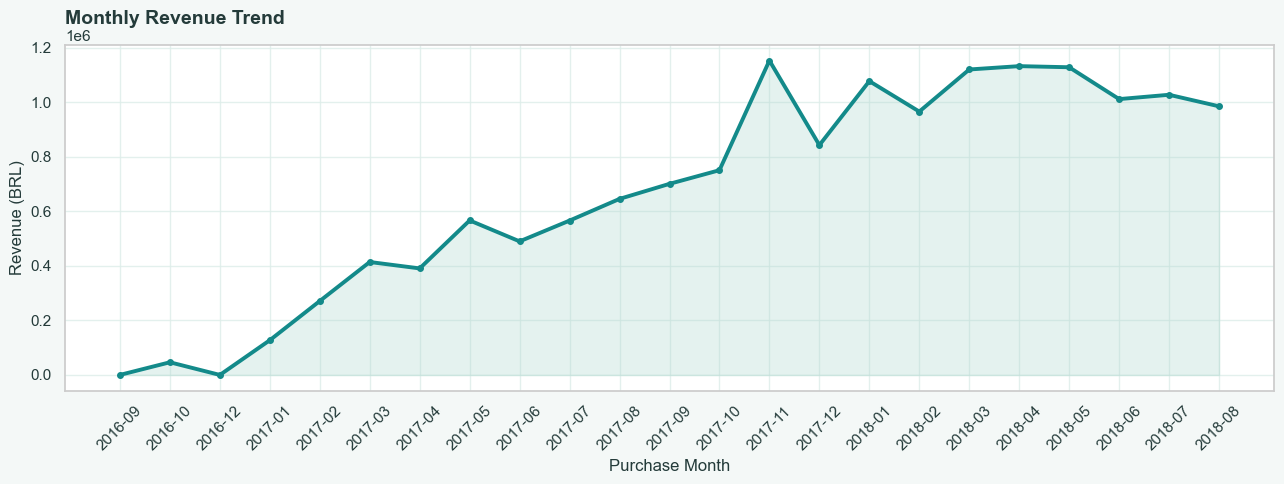

In [63]:

# Line Chart: Shows monthly revenue trends, growth, and seasonal fluctuations over time.
monthly_revenue = monthly_metrics["revenue"]

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    color=PALETTE["teal"],
    linewidth=2.8,
    marker="o",
    markersize=4
)
ax.fill_between(
    range(len(monthly_revenue)),
    monthly_revenue.values,
    color=PALETTE["mint"],
    alpha=0.3
)
ax.set_title("Monthly Revenue Trend", loc="left", pad=15)
ax.set_xlabel("Purchase Month")
ax.set_ylabel("Revenue (BRL)")
ax.tick_params(axis="x", rotation=45)
save_fig("01_monthly_revenue_trend")


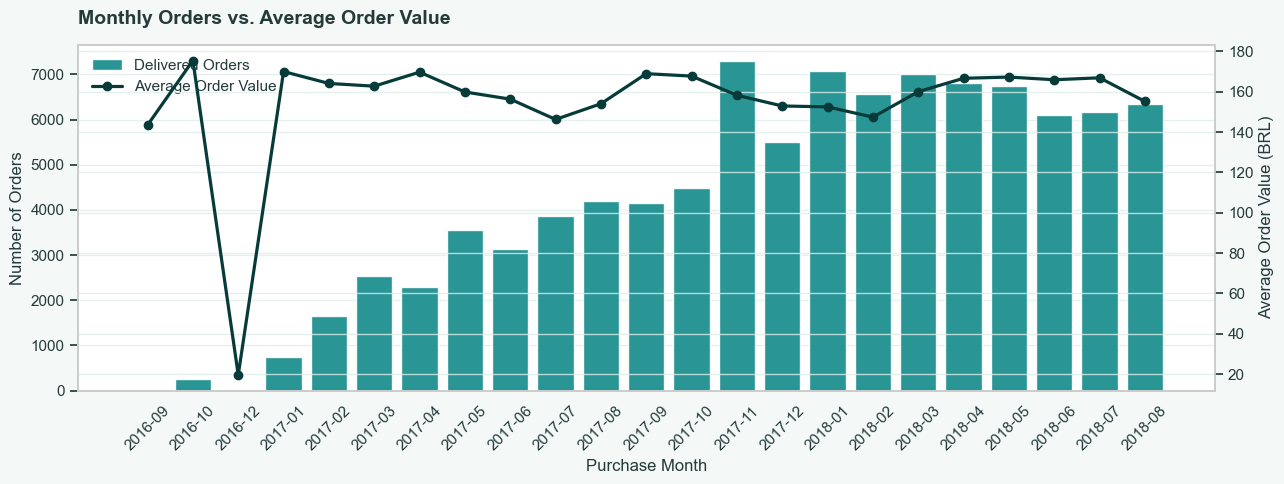

In [64]:

# Combo Chart (Bar + Line): Compares monthly order volume with average order value (AOV).
fig, ax1 = plt.subplots(figsize=(13, 5))

x = np.arange(len(monthly_metrics))
labels = monthly_metrics.index.astype(str)

ax1.bar(
    x, monthly_metrics["orders"],
    color=PALETTE["teal"], alpha=0.9, label="Delivered Orders"
)
ax1.set_xlabel("Purchase Month")
ax1.set_ylabel("Number of Orders")
ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=45)

ax2 = ax1.twinx()
ax2.plot(
    x, monthly_metrics["aov"],
    color=PALETTE["deep"], marker="o",
    linewidth=2.3, label="Average Order Value"
)
ax2.set_ylabel("Average Order Value (BRL)")

ax1.set_title("Monthly Orders vs. Average Order Value", loc="left", pad=15)
ax1.grid(axis="x", visible=False)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, frameon=False, loc="upper left")

save_fig("02_monthly_orders_aov")


In [49]:

# Check monthly order counts, revenue, and AOV to investigate the December 2016 anomaly.
print(
    monthly_metrics.loc["2016-09":"2017-02"]
    .assign(
        revenue=lambda df: df["revenue"].round(2),
        aov=lambda df: df["aov"].round(2)
    )
)


           revenue  orders     aov
month                             
2016-09     143.46       1  143.46
2016-10   46490.66     265  175.44
2016-12      19.62       1   19.62
2017-01  127482.37     750  169.98
2017-02  271239.32    1653  164.09


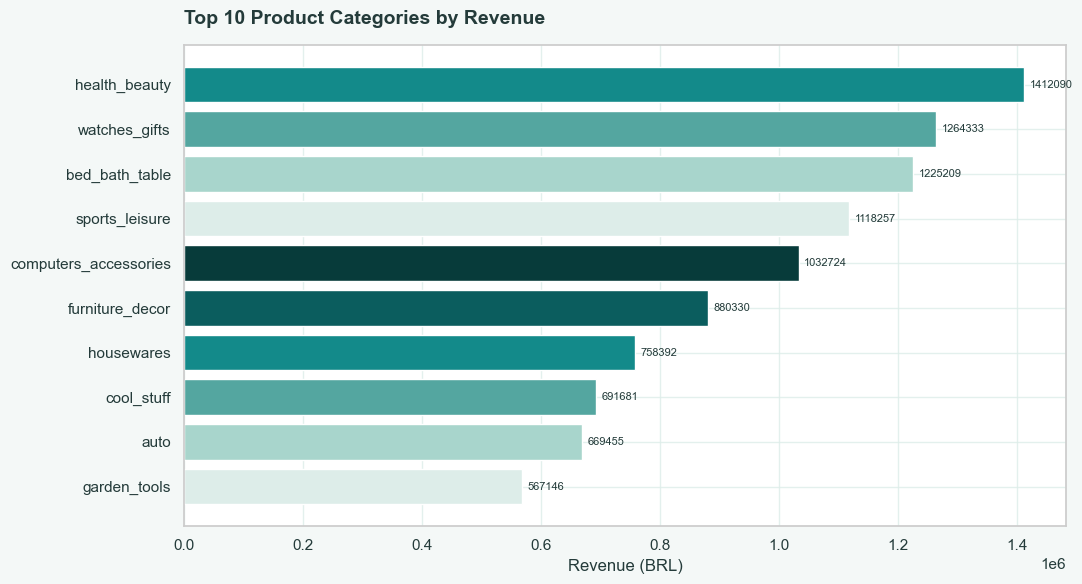

In [65]:
# Horizontal Bar Chart: Shows the top 10 product categories generating the highest revenue.
category_revenue = (
    delivered_items.groupby("category_label")["item_revenue"]
    .sum()
    .nlargest(10)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(
    category_revenue.index,
    category_revenue.values,
    color=sns.color_palette(
        [PALETTE["light"], PALETTE["mint"], PALETTE["muted"],
         PALETTE["teal"], PALETTE["dark"], PALETTE["deep"]], 10
    )
)
ax.bar_label(bars, fmt="%.0f", padding=4, fontsize=8)
ax.set_title("Top 10 Product Categories by Revenue", loc="left", pad=15)
ax.set_xlabel("Revenue (BRL)")
ax.set_ylabel("")
save_fig("03_top_categories_revenue")


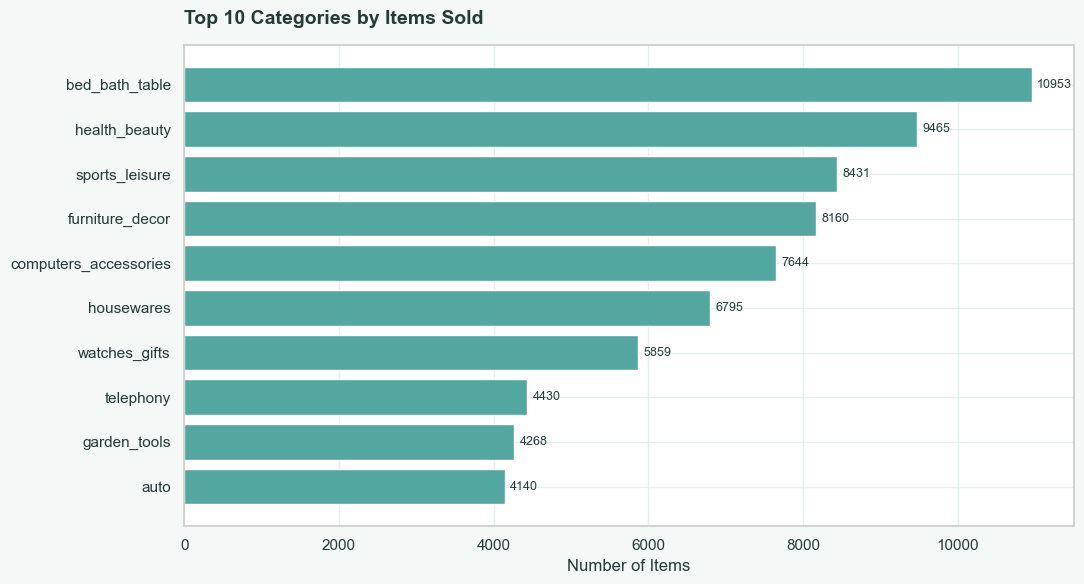

In [66]:

# Horizontal Bar Chart: Shows the top 10 product categories by number of items sold, highlighting customer demand.
category_units = (
    delivered_items.groupby("category_label")["order_item_id"]
    .count()
    .nlargest(10)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(
    category_units.index,
    category_units.values,
    color=PALETTE["muted"]
)
ax.bar_label(bars, fmt="%.0f", padding=4, fontsize=9)
ax.set_title("Top 10 Categories by Items Sold", loc="left", pad=15)
ax.set_xlabel("Number of Items")
ax.set_ylabel("")
save_fig("04_top_categories_items_sold")


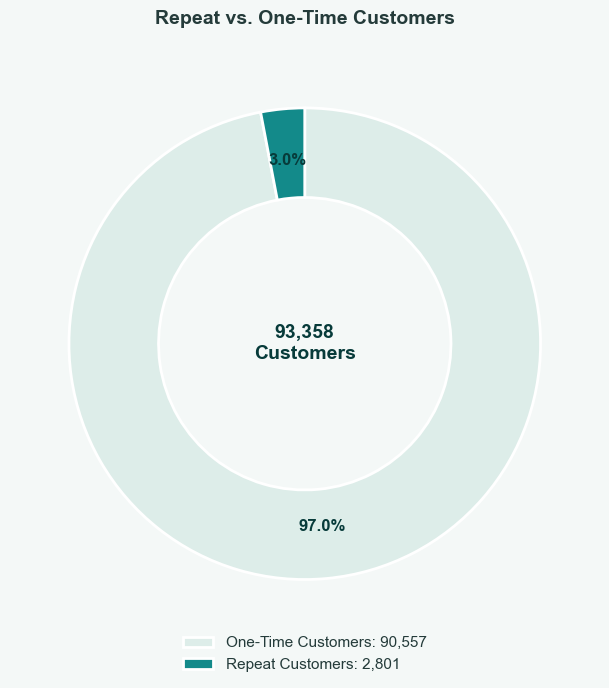

In [67]:
# Donut Chart: Shows the proportion of one-time and repeat customers, highlighting customer retention opportunities.
segments = pd.Series({
    "One-Time Customers": int((purchase_counts == 1).sum()),
    "Repeat Customers": int((purchase_counts > 1).sum())
})

fig, ax = plt.subplots(figsize=(7, 7))
wedges, _, autotexts = ax.pie(
    segments.values,
    startangle=90,
    counterclock=False,
    colors=[PALETTE["light"], PALETTE["teal"]],
    autopct="%1.1f%%",
    pctdistance=0.78,
    wedgeprops={"width": 0.38, "edgecolor": "white", "linewidth": 2}
)

for text in autotexts:
    text.set_color(PALETTE["deep"])
    text.set_fontweight("bold")

ax.text(
    0, 0, f"{segments.sum():,}\nCustomers",
    ha="center", va="center",
    fontsize=14, fontweight="bold", color=PALETTE["deep"]
)
ax.legend(
    wedges,
    [f"{k}: {v:,}" for k, v in segments.items()],
    loc="lower center", bbox_to_anchor=(0.5, -0.08),
    frameon=False
)
ax.set_title("Repeat vs. One-Time Customers", pad=18)
save_fig("05_repeat_vs_one_time_customers")


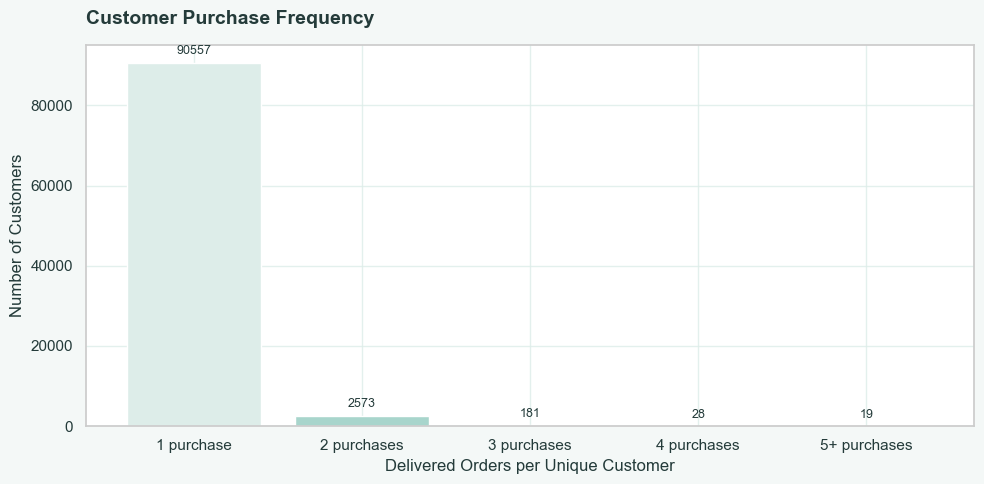

In [68]:
# Bar Chart: Shows the number of customers by purchase frequency, highlighting how many customers buy once versus repeat multiple times.
frequency_buckets = purchase_counts.clip(upper=5).value_counts().sort_index()
frequency_labels = [
    "1 purchase" if i == 1 else ("5+ purchases" if i == 5 else f"{i} purchases")
    for i in frequency_buckets.index
]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(
    frequency_labels,
    frequency_buckets.values,
    color=[PALETTE["light"], PALETTE["mint"], PALETTE["muted"],
           PALETTE["teal"], PALETTE["deep"]][:len(frequency_buckets)]
)
ax.bar_label(bars, fmt="%.0f", padding=4, fontsize=9)
ax.set_title("Customer Purchase Frequency", loc="left", pad=15)
ax.set_xlabel("Delivered Orders per Unique Customer")
ax.set_ylabel("Number of Customers")
save_fig("06_customer_purchase_frequency")


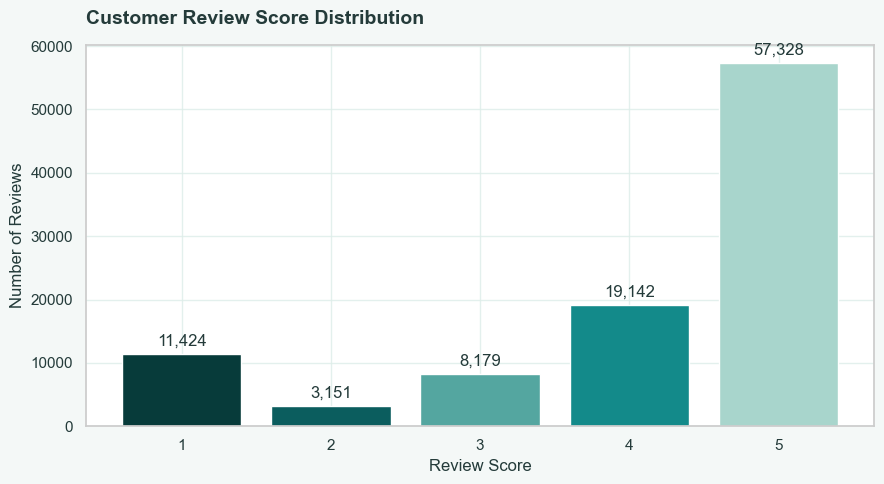

In [69]:
# Bar Chart: Shows the distribution of customer review scores (1 to 5 stars), highlighting overall satisfaction levels.
review_counts = (
    order_reviews_clean["review_score"]
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(
    review_counts.index.astype(str),
    review_counts.values,
    color=[PALETTE["deep"], PALETTE["dark"], PALETTE["muted"],
           PALETTE["teal"], PALETTE["mint"]]
)
ax.bar_label(bars, labels=[f"{v:,}" for v in review_counts.values], padding=4)
ax.set_title("Customer Review Score Distribution", loc="left", pad=15)
ax.set_xlabel("Review Score")
ax.set_ylabel("Number of Reviews")
save_fig("08_review_score_distribution")


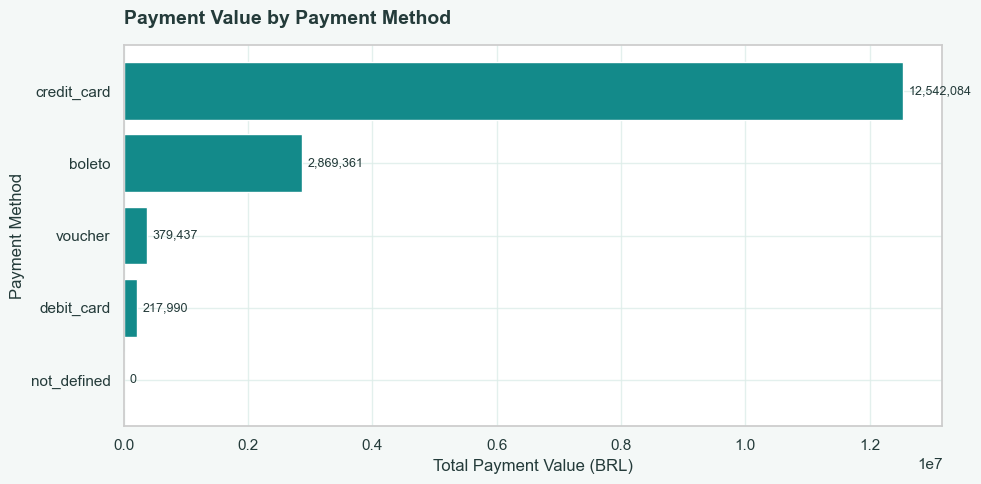

In [70]:
# Horizontal Bar Chart: Shows the total payment value by payment method, highlighting the largest contributors to payment revenue.
payment_totals = (
    order_payments_clean.groupby("payment_type")["payment_value"]
    .sum()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(
    payment_totals.index,
    payment_totals.values,
    color=PALETTE["teal"]
)
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in payment_totals.values], padding=4, fontsize=9)
ax.set_title("Payment Value by Payment Method", loc="left", pad=15)
ax.set_xlabel("Total Payment Value (BRL)")
ax.set_ylabel("Payment Method")
save_fig("10_payment_method_contribution")


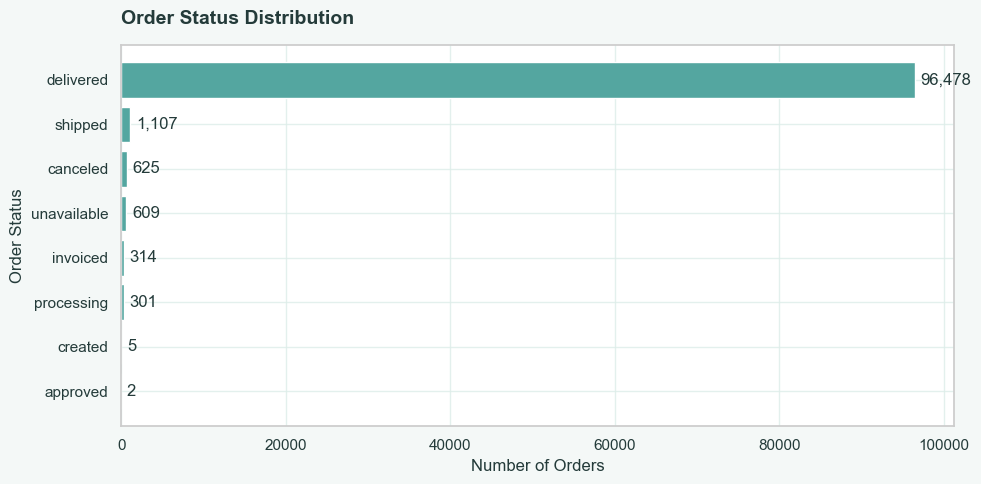

In [71]:
# Horizontal Bar Chart: Shows the number of orders by status, highlighting delivery, cancellation, and fulfillment patterns.
status_counts = orders_clean["order_status"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(
    status_counts.index,
    status_counts.values,
    color=PALETTE["muted"]
)
ax.bar_label(bars, labels=[f"{v:,}" for v in status_counts.values], padding=4)
ax.set_title("Order Status Distribution", loc="left", pad=15)
ax.set_xlabel("Number of Orders")
ax.set_ylabel("Order Status")
save_fig("11_order_status_distribution")


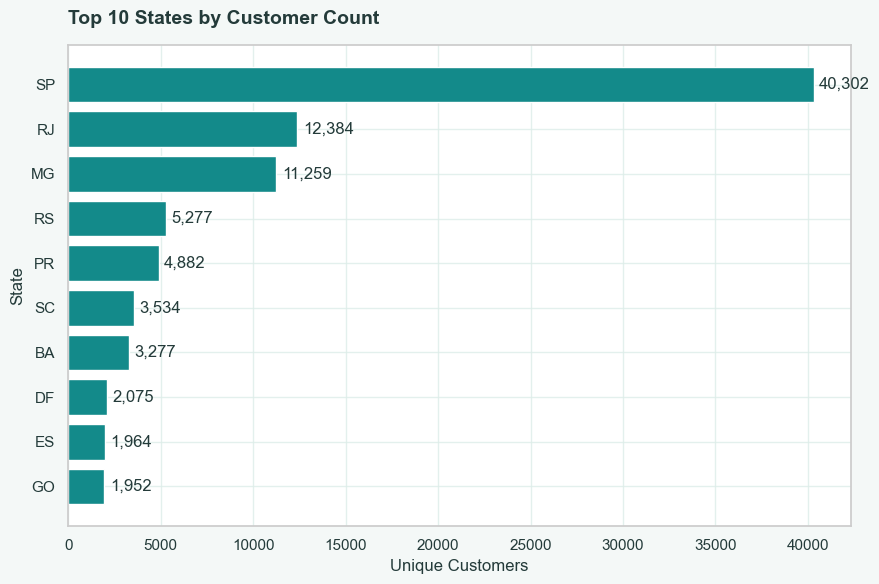

In [72]:
# Horizontal Bar Chart: Shows the top 10 states by unique customer count, highlighting the geographic distribution of customers.
state_counts = (
    customers_clean.groupby("customer_state")["customer_unique_id"]
    .nunique()
    .nlargest(10)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(
    state_counts.index,
    state_counts.values,
    color=PALETTE["teal"]
)
ax.bar_label(bars, labels=[f"{v:,}" for v in state_counts.values], padding=4)
ax.set_title("Top 10 States by Customer Count", loc="left", pad=15)
ax.set_xlabel("Unique Customers")
ax.set_ylabel("State")
save_fig("12_top_customer_states")


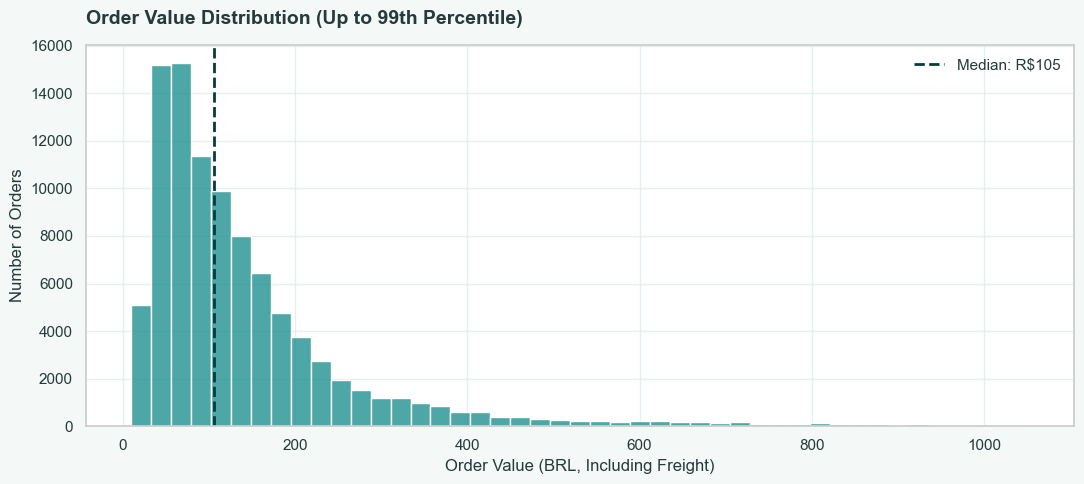

In [73]:
# Histogram: Shows the distribution of order values, highlighting typical customer spending and high-value orders.
order_values = sales_orders["order_revenue"].dropna()
upper_limit = order_values.quantile(0.99)

fig, ax = plt.subplots(figsize=(11, 5))
sns.histplot(
    order_values[order_values <= upper_limit],
    bins=45,
    color=PALETTE["teal"],
    edgecolor="white",
    ax=ax
)
ax.axvline(
    order_values.median(),
    color=PALETTE["deep"],
    linestyle="--",
    linewidth=2,
    label=f"Median: R${order_values.median():,.0f}"
)
ax.set_title("Order Value Distribution (Up to 99th Percentile)", loc="left", pad=15)
ax.set_xlabel("Order Value (BRL, Including Freight)")
ax.set_ylabel("Number of Orders")
ax.legend(frameon=False)
save_fig("13_order_value_distribution")


## Key Quantified Business Insights

- **1. Monthly Revenue Trend:** Total delivered revenue reached **R$15,419,773.75** across **96,478** delivered orders, peaking in **November 2017** (Black Friday) at **R$1,153,364.20** across **7,289** orders.
- **2. Monthly Orders vs. AOV:** Order volume scaled steadily throughout 2017–2018 while Average Order Value (AOV) remained stable around **R$159.83** (median order value: **R$105.28**).
- **3. Top Categories by Revenue:** `health_beauty` (**R$1.41M**), `watches_gifts` (**R$1.26M**), and `bed_bath_table` (**R$1.23M**) are the top three revenue drivers.
- **4. Top Categories by Items Sold:** `bed_bath_table` (**10,953** units), `health_beauty` (**9,465** units), and `sports_leisure` (**8,431** units) lead unit demand and require priority inventory allocation.
- **5. Repeat vs. One-Time Customers:** Out of **93,358** unique customers with delivered orders, **90,557 (97.00%)** purchased only once and **2,801 (3.00%)** made repeat purchases—highlighting a major retention opportunity.
- **6. Customer Purchase Frequency:** The vast majority of repeat buyers placed exactly 2 orders, making second-order conversion the highest-leverage retention milestone.
- **7. Review Score Distribution:** **77.07%** of reviews are positive (**57.78%** 5-star and **19.29%** 4-star), while **11.51%** are 1-star reviews—strongly correlated with late deliveries.
- **8. Payment Value by Method:** Credit cards account for **78.34%** of total payment value, followed by boleto (**17.92%**), vouchers (**2.37%**), and debit cards (**1.36%**).
- **9. Order Status Distribution:** **97.02%** of all orders were successfully delivered, with cancellations and unavailable orders representing less than 1.3% combined.
- **10. Top Customer States:** Customer concentration is heavily skewed toward Southeast Brazil, led by **São Paulo (SP: 40,302 customers / 41.94%)**, **Rio de Janeiro (RJ: 12,384 / 12.89%)**, and **Minas Gerais (MG: 11,259 / 11.72%)**.
- **11. Order Value Distribution:** Order values are right-skewed with a median of **R$105.28** and a mean of **R$159.83**, reflecting a core mass-market basket alongside high-ticket items.
